# Sampling: from independent draws to Markov chains — solutions

Skoltech · Bayesian machine learning

Bayesian inference often gives a posterior density that can be evaluated only
up to a normalizing constant. Prediction, uncertainty summaries, and decisions
still require integrals with respect to that posterior. Sampling turns these
integrals into numerical averages.

We study this problem through a coin model with a known posterior. Rejection
sampling produces independent posterior draws; importance sampling uses weighted
draws from another distribution; Metropolis–Hastings constructs dependent draws
using a Markov chain. The three main tasks implement these methods. An appendix
studies multimodal targets and asymmetric proposals.

The mathematical prerequisites are Bayes' rule, expectation, variance, and
elementary differentiation and integration. The implementations use NumPy arrays.


## Setup

Use Python 3.9+ with NumPy, SciPy, Matplotlib, IPython, and a notebook interface.
In a fresh environment, install `numpy scipy matplotlib ipykernel`. All examples
are generated locally. Run the cells in order.

Each task contains an implementation, checks, an experiment, and interpretation
questions. A function that still raises `NotImplementedError` is skipped by the
checks. After completing it, rerun its check and experiment cells. Appendix A
depends on Task 3 and is enabled by `RUN_APPENDIX = True` in setup.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import betaln, logsumexp
from scipy.stats import beta, norm
from IPython.display import display, Markdown

RUN_APPENDIX = True
completed = set()
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 11})

def table(headers, rows):
    def fmt(x):
        return f"{x:.5g}" if isinstance(x, (float, np.floating)) else str(x)
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(fmt, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def check_task(label, test):
    completed.discard(label)
    try:
        test()
    except NotImplementedError:
        print(f"Task {label}: unfinished; experiments will be skipped.")
        return False
    completed.add(label)
    print(f"Task {label}: checks passed.")
    return True

def ready(*labels):
    missing = [str(label) for label in labels if label not in completed]
    if missing:
        print("Complete Task " + ", ".join(missing) + " to run this experiment.")
    return not missing


## 1. Posterior expectations

Let $\theta$ denote an unknown parameter and $\mathcal D$ the observations.
Bayes' rule gives
$$\pi(\theta)=p(\theta\mid\mathcal D)
  =\frac{p(\mathcal D\mid\theta)p(\theta)}{p(\mathcal D)}.$$
The denominator is an integral over the parameter space. In a large model it
may be difficult to calculate even when the likelihood and prior can be evaluated.
We therefore write
$$\pi(\theta)=\frac{\widetilde\pi(\theta)}Z,\qquad
  Z=\int_\Theta\widetilde\pi(\theta)\,d\theta,\qquad 0<Z<\infty,$$
where $\widetilde\pi$ is a nonnegative, possibly unnormalized kernel.
Multiplying the kernel by a positive constant changes $Z$ but leaves $\pi$ unchanged.

Many posterior summaries have the form
$$I=\mathbb E_\pi[f(\theta)]=\int_\Theta f(\theta)\pi(\theta)\,d\theta.$$
A posterior mean uses $f(\theta)=\theta$. A posterior event probability uses
$f(\theta)=\mathbf1\{\theta\in A\}$. For a new observation, Bayesian prediction is
$$p(y_*\mid x_*,\mathcal D)=
  \mathbb E_\pi[p(y_*\mid x_*,\theta)].$$
Thus prediction averages conditional probabilities over parameter uncertainty.
Substituting a single best parameter value generally gives a different result.

### A coin posterior

The unknown probability of heads is $\theta\in(0,1)$. Take the prior
$\theta\sim\mathrm{Beta}(2,2)$, whose density is $6\theta(1-\theta)$.
Observe one head and five tails. For a particular observed sequence, conditional
independence gives the likelihood $\theta(1-\theta)^5$. Multiplying prior and
likelihood yields the kernel
$$\widetilde\pi(\theta)=\theta^2(1-\theta)^6\mathbf1_{(0,1)}(\theta).$$
The Beta integral is
$$B(a,b)=\int_0^1 t^{a-1}(1-t)^{b-1}\,dt
   =\frac{\Gamma(a)\Gamma(b)}{\Gamma(a+b)}.$$
Consequently $Z=B(3,7)=2!6!/9!=1/252$ and
$\pi=\mathrm{Beta}(3,7)$. This $Z$ normalizes the chosen kernel. The evidence
for the particular sequence includes the prior's factor 6 and equals $6Z$.

We estimate two quantities:
$$I_1=\mathbb E_\pi[\theta],\qquad
  I_2=\Pr_\pi(\theta>1/2).$$
Beta moments follow by inserting an extra power into the integral:
$$\mathbb E_\pi[\theta^k]=\frac{B(3+k,7)}{B(3,7)}.$$
In particular, $I_1=3/10$ and
$\operatorname{Var}_\pi(\theta)=21/1100$. The next-toss probability of heads is
$p(y_*=1\mid\mathcal D)=\mathbb E_\pi[\theta]=I_1$.
For the tail probability, put $t=1-\theta$:
$$I_2=252\int_0^{1/2}(1-t)^2t^6\,dt
  =252\left[\frac{t^7}{7}-\frac{t^8}{4}+\frac{t^9}{9}\right]_0^{1/2}
  =\frac{23}{256}.$$
These exact answers let us assess the estimators. The implementations below
must use the kernel rather than a direct Beta(3,7) sampler.


In [2]:
# Supplied target: supports scalars and arrays; never logs invalid arguments.
def log_target(theta):
    theta = np.asarray(theta, dtype=float)
    inside = (theta > 0) & (theta < 1)
    safe = np.where(inside, theta, 0.5)
    value = 2*np.log(safe) + 6*np.log1p(-safe)
    return np.where(inside, value, -np.inf)

Z = np.exp(betaln(3, 7))
EXACT_MEAN = 0.3
EXACT_TAIL = beta.sf(0.5, 3, 7)
M = 0.25**2 * 0.75**6
theta_grid = np.linspace(0.001, 0.999, 500)
table(["Reference", "Value"], [["Z", Z], ["Posterior mean", EXACT_MEAN],
                             ["P(theta > 0.5)", EXACT_TAIL],
                             ["Posterior standard deviation", np.sqrt(21/1100)]])


| Reference | Value |
| --- | --- |
| Z | 0.0039683 |
| Posterior mean | 0.3 |
| P(theta > 0.5) | 0.089844 |
| Posterior standard deviation | 0.13817 |

## 2. Monte Carlo integration

Suppose $\theta_1,\ldots,\theta_N$ are independent draws from $\pi$. Replace
the posterior by the empirical probability measure
$$\widehat\pi_N=\frac1N\sum_{i=1}^N\delta_{\theta_i}.$$
Here $\delta_{\theta_i}$ puts unit probability mass at the sampled value. Integrating
$f$ against this measure gives the Monte Carlo estimator
$$\widehat I_N=\int f\,d\widehat\pi_N
  =\frac1N\sum_{i=1}^N f(\theta_i).$$
The law of large numbers states that $\widehat I_N\to I$ almost surely when
$\mathbb E_\pi|f(\theta)|<\infty$. It explains consistency: a long sequence of
independent draws estimates the desired integral.

If $\sigma_f^2=\operatorname{Var}_\pi[f(\theta)]<\infty$, linearity of expectation
and independence imply
$$\mathbb E[\widehat I_N]=I,\qquad
  \operatorname{Var}(\widehat I_N)
  =\frac1{N^2}\sum_{i=1}^N\operatorname{Var}[f(\theta_i)]
  =\frac{\sigma_f^2}N.$$
The estimator is unbiased and has root mean squared error $\sigma_f/\sqrt N$.
The central limit theorem gives the more precise asymptotic statement
$$\sqrt N(\widehat I_N-I)\ \xrightarrow{d}\ \mathcal N(0,\sigma_f^2).$$
The finite-sample estimator is not generally exactly normal. Estimate its standard
error by
$$\widehat{\mathrm{SE}}_{\mathrm{iid}}
  =\frac{s_f}{\sqrt N},\qquad
  s_f^2=\frac1{N-1}\sum_i\big(f(\theta_i)-\widehat I_N\big)^2.$$
Under the normal approximation, $\widehat I_N\pm1.96\widehat{\mathrm{SE}}$ is an
approximate confidence interval for the numerical integral $I$ over repetitions
of the sampling algorithm. It is not a posterior credible interval for $\theta$.

Posterior standard deviation measures uncertainty about the parameter given
the observations. Monte Carlo standard error measures numerical uncertainty
about an estimated posterior summary. More draws reduce the latter; they do
not change the posterior distribution. The two scales are illustrated below.


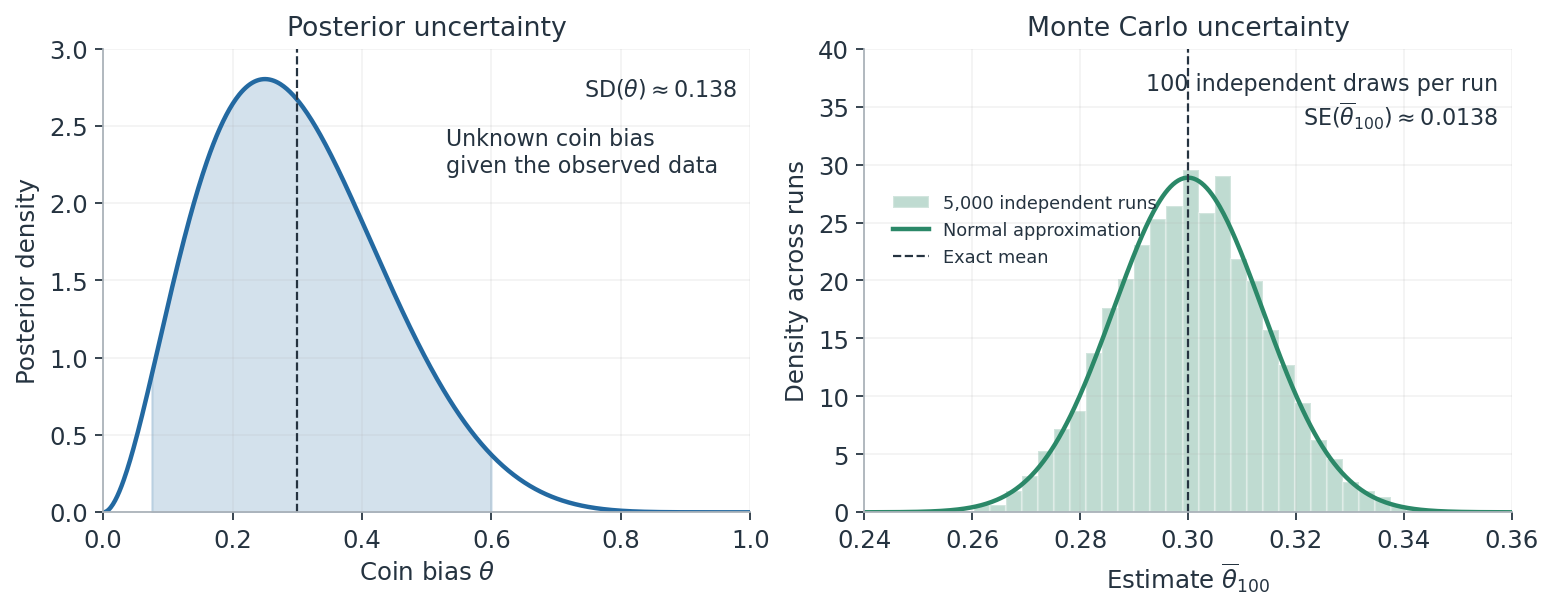

The posterior distribution describes uncertainty about the parameter. The distribution of repeated Monte Carlo means describes integration error: each mean uses 100 independent posterior draws. The horizontal scales differ.


To halve the standard error, use approximately four times as many independent
draws. The exponent $-1/2$ does not explicitly depend on dimension, but the
variance constant and the cost of obtaining useful draws can depend strongly
on dimension. The error of one random run need not decrease monotonically
as draws are added.

For a posterior event, set $f(\theta)=\mathbf1\{\theta\in A\}$. Then
$\sigma_f^2=p_A(1-p_A)$ and the same theory estimates its probability. Rare
events may require many draws: observing no event in a small sample does not
show that its probability is zero.

## 3. Inverse transform sampling

A cumulative distribution function is $F(x)=\Pr(X\leq x)$. If $F$ is continuous
and strictly increasing on its support and $U\sim\mathrm{Uniform}(0,1)$, then
$X=F^{-1}(U)$ has CDF $F$. Indeed,
$$\Pr(F^{-1}(U)\leq x)=\Pr(U\leq F(x))=F(x).$$
The transformation converts a uniform probability level into a draw in the
original units. Independent uniforms give independent transformed draws.
For CDFs with jumps or flat intervals, the generalized inverse
$F^{-1}(u)=\inf\{x:F(x)\geq u\}$ provides the corresponding construction.

For an exponential distribution with rate $\lambda>0$,
$$F(x)=1-e^{-\lambda x}\quad(x\geq0),\qquad
  F^{-1}(u)=-\frac{\log(1-u)}\lambda.$$
At rate 2, the mean is $1/2$ and variance is $1/4$. The implementation evaluates
$\log(1-u)$ as `log1p(-u)`, which is accurate when $u$ is close to zero.


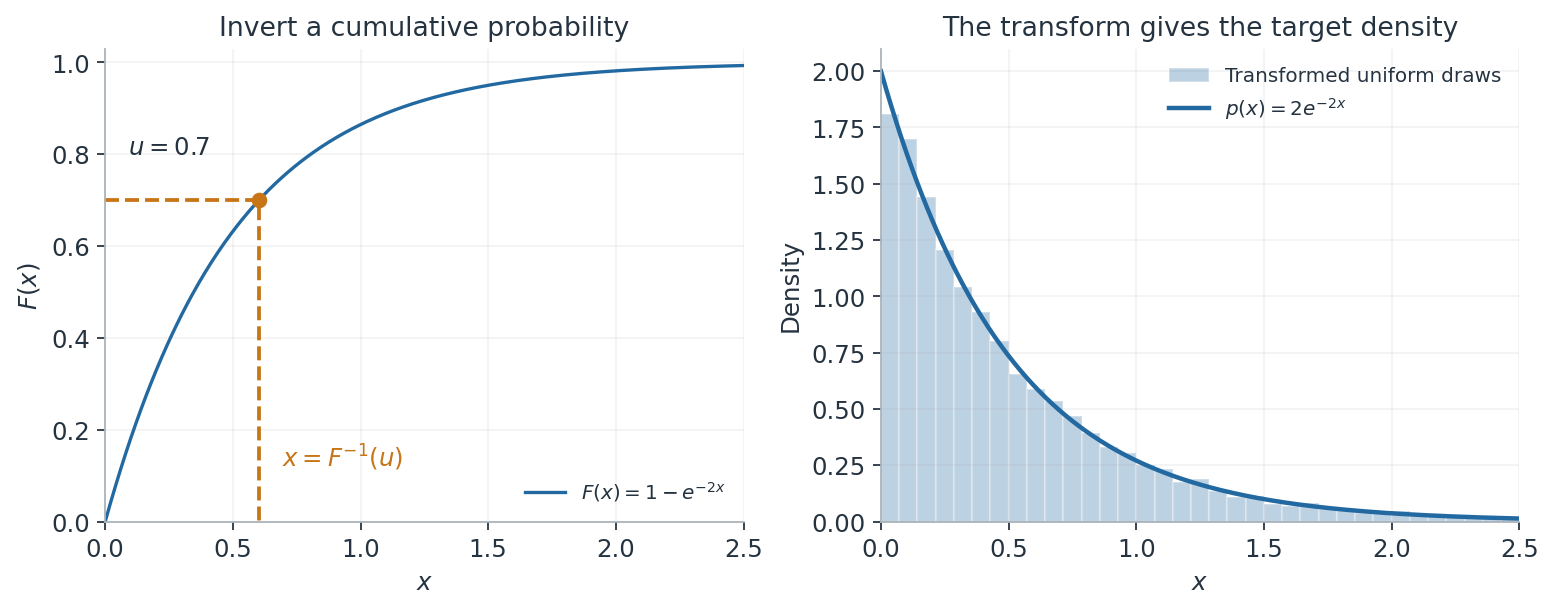

A horizontal probability level intersects the exponential CDF. Dropping vertically from that intersection to the horizontal axis gives the draw. Repeating the transformation generates the exponential density.


The following example shows the transformed sample and the RMSE of its mean
across independent replications. Inverse transforms are convenient when an
inverse CDF is available. Multivariate posteriors and unnormalized densities
usually require a different construction.


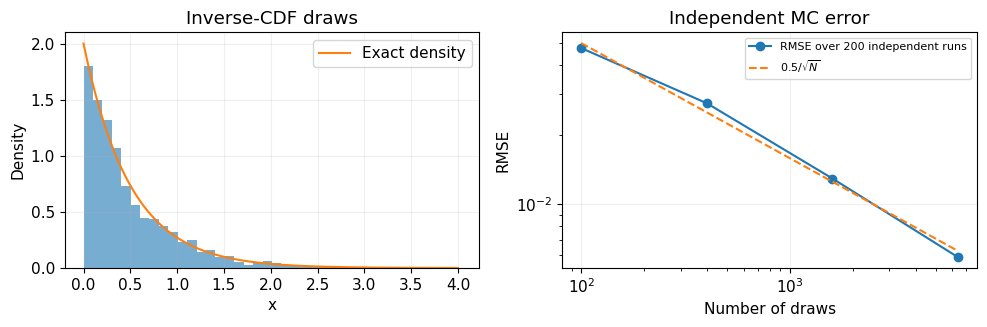

In [3]:
warmup_rng = np.random.default_rng(10)
u = warmup_rng.random(3000)
exponential_draws = -np.log1p(-u) / 2
sizes = np.array([100, 400, 1600, 6400])
rmse = []
for n in sizes:
    draws = -np.log1p(-warmup_rng.random((200, n))) / 2
    rmse.append(np.sqrt(np.mean((draws.mean(axis=1) - 0.5)**2)))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
grid = np.linspace(0, 4, 300)
axes[0].hist(exponential_draws, bins=40, density=True, alpha=0.6)
axes[0].plot(grid, 2*np.exp(-2*grid), label="Exact density")
axes[0].set(xlabel="x", ylabel="Density", title="Inverse-CDF draws")
axes[0].legend()
axes[1].loglog(sizes, rmse, "o-", label="RMSE over 200 independent runs")
axes[1].loglog(sizes, 0.5/np.sqrt(sizes), "--", label=r"$0.5/\sqrt{N}$")
axes[1].set(xlabel="Number of draws", ylabel="RMSE", title="Independent MC error")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


## 4. Rejection sampling

Let $q$ be a normalized proposal density from which independent draws are easy
to obtain. Assume its support covers the target and there is a finite constant
$M$ such that
$$\widetilde\pi(x)\leq Mq(x)\qquad\text{for every }x.$$
The inequality must hold globally, including the tails. Draw $X\sim q$ and an
independent $U\sim\mathrm{Uniform}(0,1)$, and accept when
$$U<\frac{\widetilde\pi(X)}{Mq(X)}.$$
The ratio lies between zero and one by the envelope assumption.

### Why accepted draws follow the target

For any measurable set $A$, the joint probability of proposing a point in $A$
and accepting it is
$$\Pr(X\in A,\mathrm{accept})
  =\int_A q(x)\frac{\widetilde\pi(x)}{Mq(x)}\,dx
  =\frac1M\int_A\widetilde\pi(x)\,dx.$$
Taking $A$ to be the whole support gives $\Pr(\mathrm{accept})=Z/M$. Dividing
the joint probability by this acceptance probability yields
$$\Pr(X\in A\mid\mathrm{accept})=\int_A\frac{\widetilde\pi(x)}Z\,dx.$$
Hence independent proposal trials produce independent accepted target draws.
The algorithm uses no value of $Z$ in its decisions. For an unnormalized kernel,
$M$ can be smaller than one; the acceptance probability is $Z/M$, not $1/M$.

With a uniform proposal on $(0,1)$, a trial is a uniform point in the rectangle
of width one and height $M$. Accept points below the kernel. Its area is $Z$,
so the accepted fraction is the ratio of the two areas.


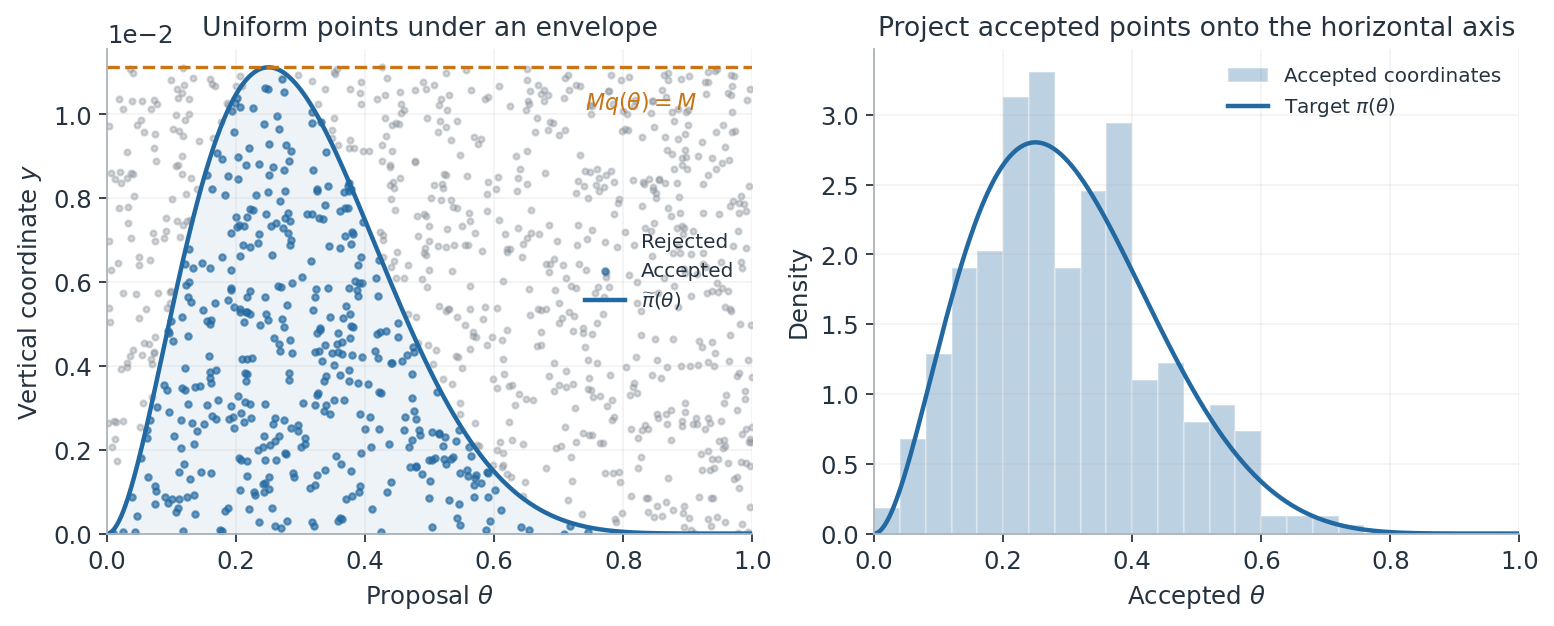

Independent uniform points below the kernel are accepted. Their horizontal coordinates follow the normalized posterior; points above the curve are discarded. The rectangle has area M and the area under the curve is Z.


### Cost and envelope validity

Under a fixed budget of $L$ proposals, the accepted count is
$K\sim\mathrm{Binomial}(L,Z/M)$. Its expectation is $LZ/M$. Alternatively,
the number of proposals needed for one accepted draw is geometric with mean
$M/Z$. A loose but valid envelope increases computation. An envelope that falls
below the kernel makes the acceptance rule invalid; clipping a ratio above one
does not restore the desired distribution.

Conditional on $K=k$, the retained values are iid target draws, so the Monte
Carlo standard error uses $k$ rather than $L$. At least two accepted draws are
needed for a sample-variance estimate. The same draws can estimate the mean
and tail probability by changing $f$.

Some target/proposal pairs admit no finite envelope. For example, a Gaussian
proposal has lighter tails than a Cauchy target, so their target-to-proposal
density ratio grows without bound in the tails. Increasing a finite $M$ cannot
fix that support-tail mismatch.

## Task 1 — Rejection sampling

1. For the uniform proposal on $(0,1)$, differentiate
   $\log\widetilde\pi(\theta)$ to locate its maximum. Justify the supplied
   $M=(1/4)^2(3/4)^6$.
2. Implement `rejection_sample(n_proposals, rng)`. Draw all uniform candidates,
   then all independent uniforms for the decisions. Return the accepted array
   and a Boolean mask of length `n_proposals`.
3. Compare observed acceptance with $Z/M$ and estimate both $I_1$ and $I_2$.
   Interpret the iid standard errors using the accepted count.

Explain what happens if the kernel and envelope are both multiplied by the same
positive constant, and why an underestimated envelope cannot be repaired by
keeping more proposals.


In [4]:
def rejection_sample(n_proposals, rng):
    '''Return (accepted: shape (n_accepted,), mask: bool shape (n_proposals,)).'''
    candidates = rng.random(n_proposals)
    uniforms = rng.random(n_proposals)
    mask = uniforms < np.exp(log_target(candidates)) / M
    return candidates[mask], mask


In [5]:
def test_rejection():
    draws, mask = rejection_sample(20000, np.random.default_rng(101))
    assert mask.shape == (20000,) and mask.dtype == np.bool_
    assert draws.ndim == 1 and len(draws) == mask.sum()
    assert np.all((draws > 0) & (draws < 1))
    assert abs(mask.mean() - Z/M) < 0.025, "Check envelope and denominator."
    se = draws.std(ddof=1) / np.sqrt(len(draws))
    assert abs(draws.mean() - EXACT_MEAN) < 6*se + 0.002
    # Reconstruct the candidates to verify that the mask identifies returned draws.
    candidates = np.random.default_rng(101).random(20000)
    np.testing.assert_array_equal(draws, candidates[mask])
    assert np.all(np.isneginf(log_target(np.array([-1., 0., 1., 2.]))))

check_task(1, test_rejection)


Task 1: checks passed.


True

Accepted 7277 / 20000 proposals; observed 0.3639, expected 0.3567.


| Quantity | Estimate | iid MC SE | Exact |
| --- | --- | --- | --- |
| E[theta] | 0.29983 | 0.0016132 | 0.3 |
| P(theta > 0.5) | 0.086712 | 0.0032991 | 0.089844 |

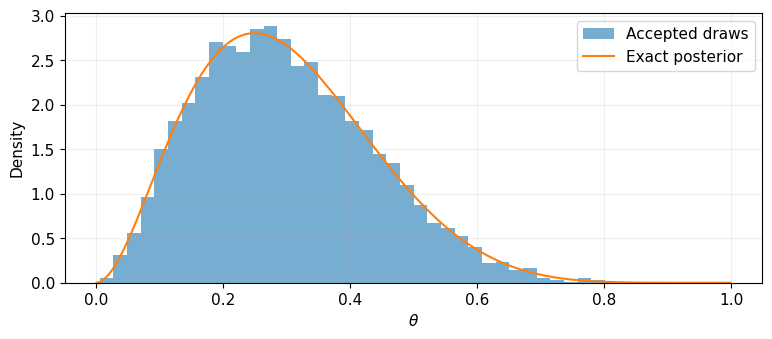

In [6]:
def iid_summary(draws):
    values = [draws, (draws > 0.5).astype(float)]
    return [[label, value.mean(), value.std(ddof=1)/np.sqrt(len(value)), exact]
            for label, value, exact in zip(
                ["E[theta]", "P(theta > 0.5)"], values, [EXACT_MEAN, EXACT_TAIL])]

if ready(1):
    rejection_draws, rejection_mask = rejection_sample(20000, np.random.default_rng(11))
    print(f"Accepted {len(rejection_draws)} / {len(rejection_mask)} proposals; "
          f"observed {rejection_mask.mean():.4f}, expected {Z/M:.4f}.")
    table(["Quantity", "Estimate", "iid MC SE", "Exact"], iid_summary(rejection_draws))
    plt.hist(rejection_draws, bins=40, density=True, alpha=0.6, label="Accepted draws")
    plt.plot(theta_grid, beta.pdf(theta_grid, 3, 7), label="Exact posterior")
    plt.xlabel(r"$\theta$")
    plt.ylabel("Density")
    plt.legend()
    plt.show()


Solution. $d\log\widetilde\pi/d\theta=2/\theta-6/(1-\theta)=0$
gives the mode $1/4$. The kernel vanishes at the endpoints and its log is strictly
concave, so $M=(1/4)^2(3/4)^6$ is a valid uniform envelope. Acceptance is
$Z/M\approx0.35674$: about 7,135 of 20,000 proposals. The posterior standard
deviation is about 0.13817; the mean's MC standard error is about 0.00164 for
7,135 accepted draws. Multiplying both kernel and envelope by the same constant
leaves every decision unchanged. An envelope below the maximum gives acceptance
probabilities above one and a biased accepted distribution if clipped.


## 5. Importance sampling

Rejection sampling spends some proposals without retaining them. Importance
sampling keeps independent draws $X_i\sim q$ and changes how much each draw
contributes to an expectation. This is a change of measure, rather than a
procedure that turns each candidate into a posterior draw.

### A normalized target

Suppose $\pi$ is normalized and $q(x)>0$ wherever $\pi(x)|f(x)|>0$. Inserting
$q(x)/q(x)$ in the integral gives
$$I=\int f(x)\pi(x)\,dx
  =\int f(x)\frac{\pi(x)}{q(x)}q(x)\,dx
  =\mathbb E_q\!\left[\frac{\pi(X)}{q(X)}f(X)\right].$$
Thus $N^{-1}\sum_i\pi(X_i)f(X_i)/q(X_i)$ is unbiased whenever the required
expectation exists. Its variance is the variance of the weighted integrand
under $q$, divided by $N$. A proposal that visits important regions often can
reduce this variance, while a poorly chosen proposal can increase it or make
it infinite.

### An unnormalized target

When only $\widetilde\pi$ is available, define $w(x)=\widetilde\pi(x)/q(x)$.
Assume $q$ covers the target support, $0<Z<\infty$, and
$\int|f(x)|\widetilde\pi(x)\,dx<\infty$. Then
$$\mathbb E_q[w(X)]=Z,\qquad
  \mathbb E_q[w(X)f(X)]=ZI.$$
Replacing these expectations by sample averages produces self-normalized
importance sampling:
$$\widehat I_{\mathrm{SNIS}}
  =\frac{\sum_i w_i f(X_i)}{\sum_i w_i}
  =\sum_i\bar w_i f(X_i),\qquad
  \bar w_i=\frac{w_i}{\sum_jw_j}.$$
The law of large numbers makes numerator and denominator converge to $ZI$ and
$Z$, so their ratio is consistent. The ratio is generally biased at finite
$N$: the expectation of a ratio is not the ratio of expectations. At $N=1$
with a positive weight, it is simply $f(X_1)$ with $X_1\sim q$, which already
shows why finite-sample unbiasedness cannot be assumed.

The estimate $N^{-1}\sum_iw_i$ of $Z$ is itself unbiased; forming a ratio is
the source of the distinction. Multiplying the kernel by a positive constant
scales all weights equally and leaves the self-normalized estimate unchanged.


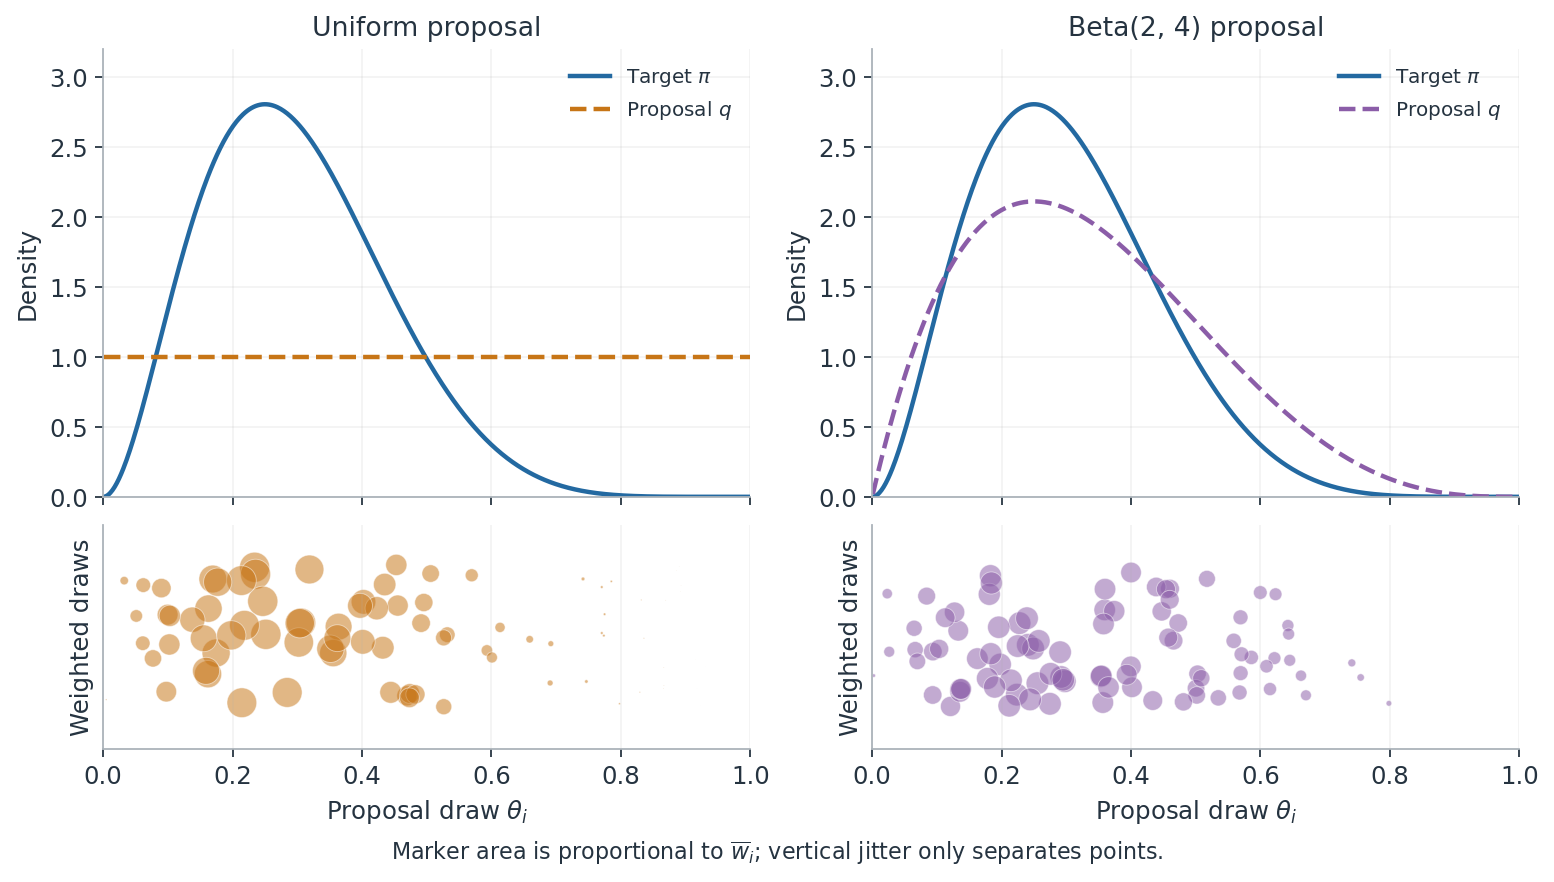

The proposal determines where candidates appear; the target-to-proposal ratio determines their contribution. Marker areas represent normalized weights on the same scale in both panels. A weighted histogram estimates the target, while an unweighted histogram estimates the proposal.


### Stable computation and error

Let $\ell_i=\log\widetilde\pi(X_i)-\log q(X_i)$. Direct exponentiation can
underflow or overflow. Instead use
$$\bar w_i=\exp\big(\ell_i-\operatorname{logsumexp}(\ell_1,\ldots,\ell_N)\big).$$
Equivalently subtract $\max_i\ell_i$, exponentiate, and divide by the sum.
At least one log weight must be finite. A zero target density gives a log
weight of $-\infty$ and normalized weight zero.

To see what controls error, write the exact identity
$$\widehat I_{\mathrm{SNIS}}-I
  =\frac{N^{-1}\sum_iw_i(f(X_i)-I)}{N^{-1}\sum_iw_i}.$$
If $\mathbb E_q[w^2(f-I)^2]<\infty$, a central limit theorem for the numerator
and convergence of the denominator to $Z$ give
$$\sqrt N(\widehat I_{\mathrm{SNIS}}-I)
  \xrightarrow{d}\mathcal N\!\left(0,
  \frac{\mathbb E_q[w^2(f-I)^2]}{Z^2}\right).$$
A corresponding plug-in estimate of its Monte Carlo standard error is
$$\widehat{\mathrm{SE}}_{\mathrm{SNIS}}
   =\sqrt{\sum_i\bar w_i^2\big(f(X_i)-\widehat I_{\mathrm{SNIS}}\big)^2}.$$
This is an asymptotic estimate, not an exact finite-sample uncertainty bound.
It can be misleading if important regions were never sampled. A usual
unweighted iid standard error of the proposal values does not estimate this
integration error.

The weight concentration diagnostic is
$$\mathrm{ESS}_w=\frac{1}{\sum_i\bar w_i^2}.$$
Since nonnegative weights sum to one, $1\leq\mathrm{ESS}_w\leq N$. Equal
weights give $N$; one dominant weight gives a value near one. Unlike the
asymptotic variance above, this expression does not contain $f$. It therefore
cannot guarantee the same accuracy for a mean, a tail probability, or another
summary, and it cannot reveal a region absent from all proposals.
See [Owen, Chapter 9](https://artowen.su.domains/mc/Ch-var-is.pdf) for further
discussion of importance-sampling estimators and diagnostics.

## Task 2 — Self-normalized importance sampling

1. Implement `snis(log_weights, values)` for matching one-dimensional arrays.
   Return `(estimate, normalized_weights, weight_ess)`.
2. Compare the uniform proposal on $(0,1)$ with $\mathrm{Beta}(2,4)$ using
   2,000 proposals each. Estimate $I_1$ and $I_2$ from the same weights.
3. Inspect the repeated experiment's empirical bias, RMSE, and weight ESS.
   Compare these with the single-run plug-in standard errors.

Both proposals cover the target support and have the relevant finite weighted
second moments here. Explain why a large weight ESS need not imply a better
estimate for every function, and what changes if the kernel is multiplied by 100.


In [7]:
def snis(log_weights, values):
    '''Matching (N,) arrays; log weights finite or -inf, at least one finite.

    Return (scalar estimate, normalized_weights shape (N,), scalar weight ESS).
    values must be finite.
    '''
    weights = np.exp(log_weights - logsumexp(log_weights))
    estimate = np.dot(weights, values)
    ess = 1.0 / np.sum(weights**2)
    return estimate, weights, ess


In [8]:
def test_snis():
    estimate, weights, ess = snis(np.log([1., 2., 1.]), np.array([0., 1., 2.]))
    np.testing.assert_allclose(weights, [0.25, 0.5, 0.25])
    np.testing.assert_allclose([estimate, ess], [1., 8/3])
    for shift in [-10000., 10000.]:
        result = snis(np.log([1., 2., 1.]) + shift, np.array([0., 1., 2.]))
        np.testing.assert_allclose(result[0], estimate, atol=1e-10)
        np.testing.assert_allclose(result[1], weights, atol=1e-10)
        np.testing.assert_allclose(result[2], ess, atol=1e-10)
    e, w, neff = snis(np.array([-np.inf, 0., -np.inf]), np.array([7., 3., 9.]))
    np.testing.assert_allclose([e, neff], [3., 1.])
    np.testing.assert_array_equal(w, [0., 1., 0.])

check_task(2, test_snis)


Task 2: checks passed.


True

| Proposal | Mean | Mean MC SE | Tail | Tail MC SE | Weight ESS (N=2000) |
| --- | --- | --- | --- | --- | --- |
| Uniform | 0.29475 | 0.0032998 | 0.083628 | 0.0051521 | 964.91 |
| Beta(2,4) | 0.30207 | 0.0027988 | 0.091948 | 0.0051096 | 1798.9 |

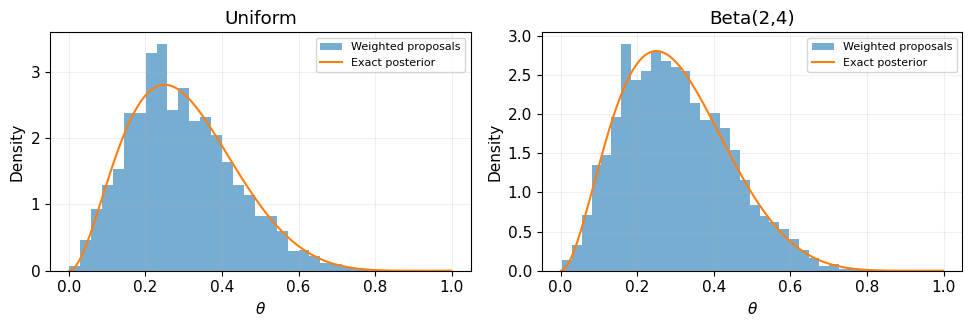

| Proposal | Mean empirical bias | Mean RMSE | Tail RMSE | Mean weight ESS (N=500) |
| --- | --- | --- | --- | --- |
| Uniform | 0.00048846 | 0.0062375 | 0.010959 | 243.8 |
| Beta(2,4) | 0.00076101 | 0.0055086 | 0.011734 | 450.56 |

In [9]:
# Supplied proposal sampler and log density, with one RNG per experiment.
def importance_proposals(name, n, rng):
    if name == "Uniform":
        x = rng.random(n)
        return x, np.zeros(n)
    if name == "Beta(2,4)":
        x = rng.beta(2, 4, size=n)
        return x, beta.logpdf(x, 2, 4)
    raise ValueError(name)

if ready(2):
    importance_rows = []
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for j, name in enumerate(["Uniform", "Beta(2,4)"]):
        x, log_q = importance_proposals(name, 2000, np.random.default_rng(20+j))
        mean, weights, ess = snis(log_target(x)-log_q, x)
        tail, _, _ = snis(log_target(x)-log_q, (x > 0.5).astype(float))
        mean_se = np.sqrt(np.sum(weights**2 * (x-mean)**2))
        tail_se = np.sqrt(np.sum(weights**2 * ((x > 0.5)-tail)**2))
        importance_rows.append([name, mean, mean_se, tail, tail_se, ess])
        axes[j].hist(x, bins=35, weights=weights, density=True, alpha=0.6,
                     label="Weighted proposals")
        axes[j].plot(theta_grid, beta.pdf(theta_grid, 3, 7), label="Exact posterior")
        axes[j].set(title=name, xlabel=r"$\theta$", ylabel="Density")
        axes[j].legend(fontsize=8)
    table(["Proposal", "Mean", "Mean MC SE", "Tail", "Tail MC SE", "Weight ESS (N=2000)"],
          importance_rows)
    plt.tight_layout()
    plt.show()

    # Independent repetitions assess estimator error, not posterior spread.
    replication_rows = []
    for j, name in enumerate(["Uniform", "Beta(2,4)"]):
        rng = np.random.default_rng(120+j)
        estimates, tails, esses = [], [], []
        for _ in range(100):
            x, log_q = importance_proposals(name, 500, rng)
            est, _, ess = snis(log_target(x)-log_q, x)
            tail, _, _ = snis(log_target(x)-log_q, (x > 0.5).astype(float))
            estimates.append(est)
            tails.append(tail)
            esses.append(ess)
        estimates, tails = np.array(estimates), np.array(tails)
        replication_rows.append([
            name, np.mean(estimates)-EXACT_MEAN,
            np.sqrt(np.mean((estimates-EXACT_MEAN)**2)),
            np.sqrt(np.mean((tails-EXACT_TAIL)**2)), np.mean(esses)])
    table(["Proposal", "Mean empirical bias", "Mean RMSE", "Tail RMSE", "Mean weight ESS (N=500)"],
          replication_rows)


Solution. Beta(2,4) places more proposals where the posterior is large, so
it usually gives more even weights and a larger weight ESS here. In these
fixed experiments it reduces the RMSE of the posterior mean, while the tail
RMSE is slightly larger. The integrand differs, and 100 replications still
have sampling variability. This is an empirical comparison, not a universal
optimality claim.
Weight ESS alone ignores whether a region was missed. Multiplying the kernel
by 100 adds a constant to all log weights and changes neither normalized weights
nor estimates. A small empirical bias over 100 replications does not establish
that the ratio estimator is unbiased.


## 6. Markov chain Monte Carlo

Rejection sampling needs a global envelope. Importance sampling needs a
proposal that covers the target with well-behaved weights. A Markov chain
takes a different approach: its next draw depends on its current state, and
its long-run occupation frequencies are designed to match the target.

A time-homogeneous Markov chain has transition kernel $K(x,A)$, the probability
that its next state lies in $A$ given current state $x$. The Markov property is
$$\Pr(X_{t+1}\in A\mid X_t,\ldots,X_0)=K(X_t,A).$$
A probability measure $\pi$ is invariant when
$$\pi(A)=\int K(x,A)\pi(dx).$$
Starting with $X_0\sim\pi$ then preserves the marginal law at every step.
Successive states can still be dependent. Starting from an arbitrary state
requires convergence to the invariant law; invariance alone does not provide it.

### Metropolis–Hastings acceptance

Given current state $x$ with positive target density, propose $y\sim q(\cdot\mid x)$.
Accept with probability
$$\alpha(x,y)=\min\!\left(1,
  \frac{\widetilde\pi(y)q(x\mid y)}{\widetilde\pi(x)q(y\mid x)}\right).$$
If a candidate has no reverse proposal probability or zero target density,
its acceptance probability is zero. The unknown target normalizer cancels.
A rejection leaves the next state at $x$.

The transition includes both moves and a point mass for staying:
$$K(x,dy)=q(y\mid x)\alpha(x,y)\,dy+r(x)\delta_x(dy),\qquad
  r(x)=1-\int q(y\mid x)\alpha(x,y)\,dy.$$
For distinct $x,y$, multiply the move probability by the target:
$$\pi(x)q(y\mid x)\alpha(x,y)
  =\min\{\pi(x)q(y\mid x),\pi(y)q(x\mid y)\}.$$
The expression is unchanged when $x$ and $y$ are exchanged. This is detailed
balance for moves; the holding mass is also balanced. Integrating the balanced
probability flow shows that $\pi$ is invariant. Detailed balance is a sufficient
condition for invariance, not a requirement for every valid MCMC algorithm.

To reach this invariant law from an arbitrary start, the chain must be able to
explore the relevant support and must satisfy appropriate recurrence and
aperiodicity conditions. An ergodic chain obeys a law of large numbers for
integrable functions. A useful central limit theorem and finite standard error
require additional moment and dependence conditions.

### Gaussian random walk

Use $Y=X+s\epsilon$, where $\epsilon\sim\mathcal N(0,1)$ and $s>0$ is a
proposal standard deviation. The Gaussian density is symmetric in $y-x$:
$q(y\mid x)=q(x\mid y)$. Thus
$$\log\alpha(x,y)=\min(0,\log\widetilde\pi(y)-\log\widetilde\pi(x)).$$
Generate an independent uniform $U$ and accept when $\log U<\log\alpha$.
Log arithmetic avoids exponentiating very large or small density ratios.


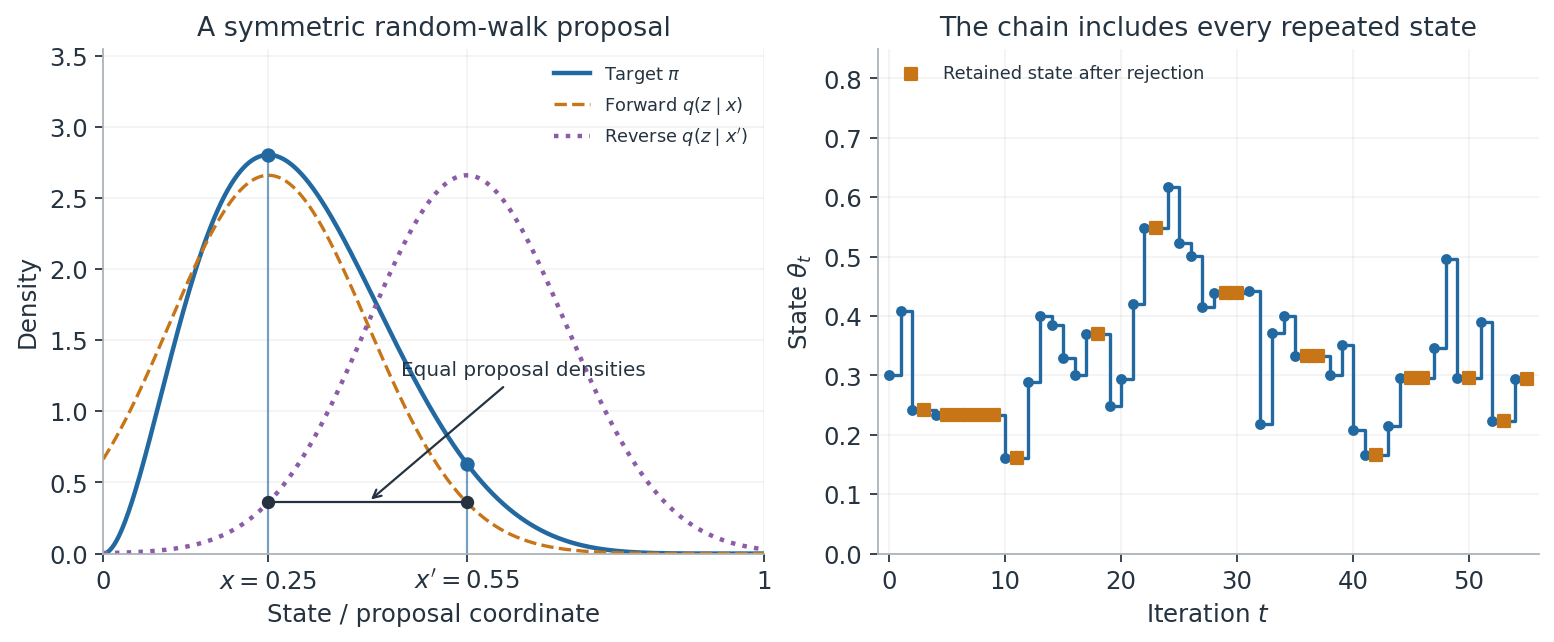

For a Gaussian random walk, the proposal density at the marked candidate equals the reverse proposal density at the current state. The target ratio determines acceptance. Rejected proposals produce repeated states in the recorded chain.


For the coin posterior, propose on the whole real line. A candidate outside
$(0,1)$ has log target $-\infty$ and is rejected. Conditioning the proposal to
stay inside the interval changes its density: a truncated Gaussian has a
normalization depending on its current state, so its forward and reverse
proposal terms no longer cancel. Moving candidates into the interior by
clipping also changes the transition. Keep the stated proposal and reject
out-of-support candidates.

Every iteration contributes a recorded state, including a repeated state after
rejection. Let $a(x)=\int q(y\mid x)\alpha(x,y)\,dy$ be the probability of
moving away from $x$. Keeping only accepted moves generally gives the jump
chain, whose invariant law is proportional to $\pi(x)a(x)$ rather than $\pi(x)$.
Removing repeated states therefore changes posterior occupation frequencies.

A small step often accepts many proposals but moves slowly. A large step can
reach distant regions but may often propose implausible states. Acceptance
alone does not measure the accuracy of posterior summaries. We compare scales
using traces, agreement between chains, and function-specific error estimates.

## Task 3 — Random-walk Metropolis–Hastings

1. Implement the vectorized sampler below. Update four independent scalar
   chains, using fresh proposal noise and acceptance uniforms for each chain.
   Store the state after every decision and return acceptance rates per chain.
2. Compare $s\in\{0.01,0.15,1.0\}$ with four dispersed starts and the same
   number of transitions. Remove the specified initial segment before summaries.
3. Use the diagnostics below to choose a scale for this example. Compare the
   naive iid standard error with the batch-means standard error for each estimand.

Discarding an initial segment, often called burn-in, reduces sensitivity to
initialization when the chain is approaching its invariant law. A fixed burn-in
does not establish stationarity and does not remove autocorrelation.


In [10]:
def random_walk_metropolis(log_density, initial, proposal_std, n_steps, rng):
    '''Vectorized scalar chains; initial shape (n_chains,), finite log density.

    log_density maps shape (n_chains,) to that same shape. proposal_std > 0.
    Return (samples shape (n_chains, n_steps), acceptance_rate per chain).
    samples[:, t] is the state AFTER decision t. Do not modify initial.
    '''
    current = np.array(initial, dtype=float, copy=True)
    current_logp = log_density(current)
    n_chains = len(current)
    samples = np.empty((n_chains, n_steps))
    accepted = np.zeros(n_chains, dtype=int)
    for t in range(n_steps):
        candidate = current + proposal_std*rng.normal(size=n_chains)
        candidate_logp = log_density(candidate)
        log_alpha = np.minimum(0., candidate_logp-current_logp)
        accept = np.log(rng.random(n_chains)) < log_alpha
        current = np.where(accept, candidate, current)
        current_logp = np.where(accept, candidate_logp, current_logp)
        accepted += accept
        samples[:, t] = current
    return samples, accepted/n_steps


In [11]:
def test_metropolis():
    initial = np.array([0.05, 0.3, 0.8])
    original = initial.copy()
    samples, rates = random_walk_metropolis(log_target, initial, 0.15, 4000,
                                           np.random.default_rng(301))
    assert samples.shape == (3, 4000) and rates.shape == (3,)
    assert np.all((samples > 0) & (samples < 1))
    np.testing.assert_array_equal(initial, original)
    assert np.all((rates > 0) & (rates < 1))
    previous = np.column_stack([initial, samples[:, :-1]])
    # A rejected state is retained, and every accepted continuous proposal moves.
    np.testing.assert_allclose(np.mean(samples != previous, axis=1), rates)
    assert abs(samples[:, 1000:].mean()-EXACT_MEAN) < 0.035
    shifted, shifted_rates = random_walk_metropolis(
        lambda x: log_target(x)+10000., initial, 0.15, 4000,
        np.random.default_rng(301))
    np.testing.assert_array_equal(samples, shifted)
    np.testing.assert_array_equal(rates, shifted_rates)
    # Almost all proposals leave this narrow support, so repeated states matter.
    narrow = lambda x: np.where(np.abs(x) < 0.001, 0., -np.inf)
    stuck, rejected_rates = random_walk_metropolis(
        narrow, np.array([0.]), 100., 20, np.random.default_rng(302))
    np.testing.assert_array_equal(stuck, np.zeros((1, 20)))
    np.testing.assert_array_equal(rejected_rates, [0.])

check_task(3, test_metropolis)


Task 3: checks passed.


True

## 7. Monte Carlo error for dependent draws

Suppose a stationary chain is used to estimate $I=\mathbb E_\pi f(X)$.
Write $Y_t=f(X_t)$, $\sigma_f^2=\operatorname{Var}_\pi f(X)$ and
$\rho_f(k)=\operatorname{Corr}(Y_t,Y_{t+k})$. Expanding the variance of a sum
counts $N-k$ pairs at each lag $k$, giving the exact finite-$N$ expression
$$\operatorname{Var}(\widehat I_N)
  =\frac{\sigma_f^2}{N}\left[1+2\sum_{k=1}^{N-1}
    \left(1-\frac{k}{N}\right)\rho_f(k)\right].$$
Independent draws have all nonzero-lag correlations zero. Positive dependence
generally raises the variance. If the autocorrelations are absolutely summable,
the large-$N$ variance factor is the integrated autocorrelation time
$$\tau_f=1+2\sum_{k=1}^\infty\rho_f(k),\qquad
  \operatorname{Var}(\widehat I_N)\approx\frac{\sigma_f^2\tau_f}{N}.$$
The equivalent number of independent draws is
$\mathrm{ESS}_{\mathrm{MCMC},f}=N/\tau_f$. This depends on the function $f$:
a posterior mean and a tail indicator need not have the same autocorrelation.
Negative correlation can even produce ESS greater than $N$. This is distinct
from the importance-weight ESS, which is always at most $N$.

These variance expressions describe a stationary chain. They do not account
for transient bias from initialization or failure to visit an important region.
Diagnostics must examine both exploration and dependence.

### Traces, chain agreement, and split Rhat

A trace plot preserves iteration order and shows long stays, slow drift, and
separation between chains. A histogram discards that order. Run independent
chains from dispersed points so that persistent disagreement is easier to detect.

The classic split $\widehat R$ first splits each retained chain into two halves.
For the resulting $m$ sequences of length $n$, let $\bar y_j$ and $s_j^2$ be
their means and sample variances. Define
$$W=\frac1m\sum_js_j^2,\qquad
  B=\frac{n}{m-1}\sum_j(\bar y_j-\bar y)^2,\qquad
  \widehat R=\sqrt{\frac{(n-1)W/n+B/n}{W}}.$$
Here $\bar y$ is the average sequence mean. Values substantially above one
flag disagreement within or between runs. A value near one cannot prove that
all relevant regions were explored; all chains can miss the same region.
Constant sequences also make variance-based diagnostics undefined or uninformative.

The code uses the classic formula to make its mechanism explicit. Modern
rank-normalized and folded Rhat, together with bulk and tail ESS, address
additional failures such as different chain scales or heavy tails; see
[Vehtari et al. (2021)](https://arxiv.org/abs/1903.08008).

### Batch-means standard error

Divide each retained chain into $a$ consecutive batches of length $b$. For
chain $c$ and batch $j$, calculate
$$\bar Y_{cj}=\frac1b\sum_{t=(j-1)b+1}^{jb}Y_{ct}.$$
If batches are long enough to capture the chain's dependence, their means
behave approximately like independent values with variance
$\sigma_f^2\tau_f/b$. Thus
$$\widehat S_c=b\operatorname{Var}_j(\bar Y_{cj})$$
estimates the chain's long-run variance. For $C$ independent chains, each with
$n=ab$ used draws, the estimated standard error of the pooled mean is
$$\widehat{\mathrm{SE}}_{\mathrm{batch}}
  =\sqrt{\frac{C^{-1}\sum_c\widehat S_c}{Cn}}.$$
The implementation trims any incomplete last batch and uses sample variances
with `ddof=1`. It reports an approximate batch ESS by dividing the mean
within-chain variance by the squared batch standard error. Capping this estimate
at the draw count is a reporting convention, not a general bound on MCMC ESS.

Short batches can miss long-range dependence, while very long batches leave
too few batch means to estimate variance reliably. Increasing the run length
should allow both the number and length of batches to grow. Here batches of
100 illustrate the calculation; compare a larger batch length for a slow chain.
Read batch estimates together with traces and chain agreement, especially
when the chain has not mixed. The code also reports within-chain lag-one
correlation as a limited view of local persistence.


| Step | Quantity | Accept | Estimate | iid SE | Batch SE | Batch ESS | Classic split Rhat | Lag-1 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.01 | Mean | 0.97713 | 0.32253 | 0.00089083 | 0.0084857 | 216.43 | 1.2353 | 0.99677 |
| 0.01 | Tail | 0.97713 | 0.08915 | 0.002015 | 0.016514 | 290.95 | 1.0889 | 0.9258 |
| 0.15 | Mean | 0.69054 | 0.30148 | 0.00097065 | 0.0025954 | 2795.3 | 1.0015 | 0.74799 |
| 0.15 | Tail | 0.69054 | 0.0875 | 0.0019981 | 0.0046186 | 3740.4 | 1.0008 | 0.6345 |
| 1 | Mean | 0.167 | 0.29749 | 0.00093844 | 0.002627 | 2546.9 | 1.0025 | 0.80879 |
| 1 | Tail | 0.167 | 0.07965 | 0.0019145 | 0.0057146 | 2244.2 | 1.0012 | 0.81108 |

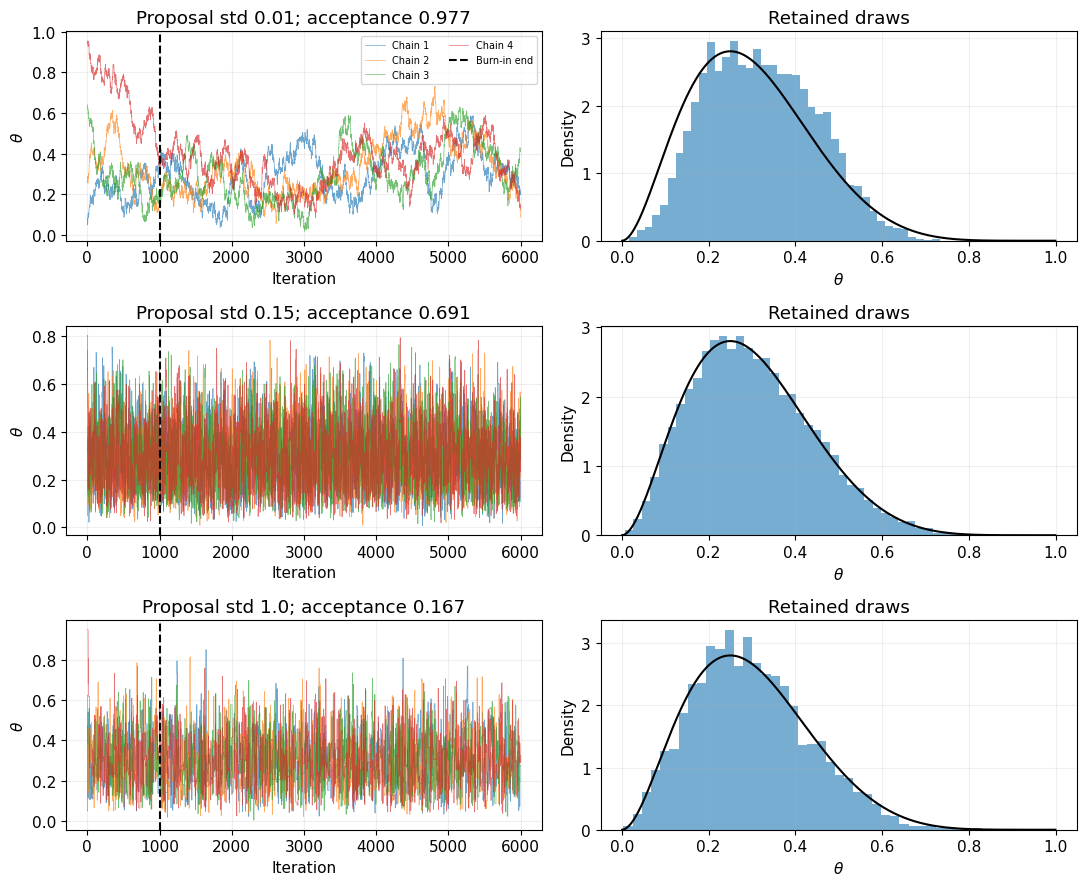

In [12]:
def classic_split_rhat(chains):
    n = chains.shape[1] // 2
    split = np.concatenate([chains[:, :n], chains[:, -n:]], axis=0)
    within = np.mean(np.var(split, axis=1, ddof=1))
    between = n*np.var(split.mean(axis=1), ddof=1)
    if within == 0:
        return np.inf if between > 0 else np.nan
    return np.sqrt(((n-1)*within/n + between/n)/within)

def chain_diagnostics(values, batch_size=100):
    # values: (independent chains, retained iterations), one scalar estimand.
    m, n = values.shape
    n_batches = n // batch_size
    if n_batches < 2:
        raise ValueError("Need at least two batches per chain.")
    used = values[:, :n_batches*batch_size]
    batch_means = used.reshape(m, n_batches, batch_size).mean(axis=2)
    long_run_var = batch_size*np.var(batch_means, axis=1, ddof=1)
    mcse = np.sqrt(long_run_var.mean()/used.size)
    marginal_var = np.var(used, axis=1, ddof=1).mean()
    ess = np.clip(marginal_var/mcse**2, 1, used.size) if mcse > 0 else np.nan
    lag1 = []
    for chain in used:
        lag1.append(np.corrcoef(chain[:-1], chain[1:])[0, 1]
                    if np.var(chain) > 0 else np.nan)
    return {"mean": used.mean(), "iid_se": used.std(ddof=1)/np.sqrt(used.size),
            "batch_se": mcse, "batch_ess": ess,
            "rhat": classic_split_rhat(used), "lag1": np.mean(lag1)}

if ready(3):
    mh_results = {}
    mh_rows = []
    fig, axes = plt.subplots(3, 2, figsize=(11, 9))
    initial = np.array([0.05, 0.25, 0.65, 0.95])
    for row, step in enumerate([0.01, 0.15, 1.0]):
        samples, rates = random_walk_metropolis(
            log_target, initial, step, 6000, np.random.default_rng(30+row))
        retained = samples[:, 1000:]
        mh_results[step] = (samples, retained, rates)
        for label, values in [("Mean", retained),
                              ("Tail", (retained > 0.5).astype(float))]:
            d = chain_diagnostics(values)
            mh_rows.append([step, label, rates.mean(), d["mean"], d["iid_se"],
                            d["batch_se"], d["batch_ess"], d["rhat"], d["lag1"]])
        for j, chain in enumerate(samples):
            axes[row, 0].plot(chain, linewidth=0.5, alpha=0.65, label=f"Chain {j+1}")
        axes[row, 0].axvline(1000, color="black", linestyle="--", label="Burn-in end")
        axes[row, 0].set(title=f"Proposal std {step}; acceptance {rates.mean():.3f}",
                         xlabel="Iteration", ylabel=r"$\theta$")
        axes[row, 1].hist(retained.ravel(), bins=40, density=True, alpha=0.6)
        axes[row, 1].plot(theta_grid, beta.pdf(theta_grid, 3, 7), color="black")
        axes[row, 1].set(xlabel=r"$\theta$", ylabel="Density", title="Retained draws")
    axes[0, 0].legend(fontsize=7, ncol=2)
    table(["Step", "Quantity", "Accept", "Estimate", "iid SE", "Batch SE",
           "Batch ESS", "Classic split Rhat", "Lag-1"], mh_rows)
    plt.tight_layout()
    plt.show()


Solution. The tiny step accepts almost every proposal but explores slowly:
traces persist, lag correlations are high, and chain means can disagree. The
very large step wastes proposals outside the support or in low-density regions.
The middle scale is a useful choice in this example because it explores the
posterior with less persistence and gives more stable estimates. Compare its
batch SE and split Rhat as well as its acceptance. There is no universal optimal
acceptance percentage for this problem class. Removing burn-in reduces sensitivity
to initialization; it does not remove autocorrelation or establish convergence.
Keeping only accepted states would change the occupation frequencies and bias
the sampler. A smooth pooled histogram can hide chain-specific failures.


## Comparing the methods

| Method | Required information | Output | Error or efficiency issue |
| --- | --- | --- | --- |
| Inverse transform | A tractable inverse CDF | Independent target draws | Whether the inverse is available |
| Rejection | Sampleable proposal and a global envelope | Independent accepted target draws | Envelope validity and proposals per acceptance |
| Importance | Sampleable, evaluable proposal and target kernel | Weighted independent proposal draws | Support, tails, and integrand-specific weight variance |
| Metropolis–Hastings | Evaluable target kernel and a valid proposal | Every state of a dependent chain | Exploration, initialization, and autocorrelation |

These demonstrations use different proposal budgets and are not a controlled
computational benchmark. An accuracy comparison should account for target
evaluations, rejected proposals, burn-in, and the cost of sampling the proposal.

Discuss the following questions using the derivations and experiments.

1. How does each method avoid, or require, the unknown normalizing constant?
2. Which outputs are independent target draws, and which require weights or
   a correlated-draw error estimate?
3. Which failures can more draws reduce, and which require changing the proposal
   or the algorithm?
4. Let $\sigma(z)=1/(1+e^{-z})$ be the sigmoid function. For logistic regression
   with coefficient draws $\theta^{(i)}$, how would you
   estimate $\mathbb E[\sigma(\theta_0+x_*\theta_1)\mid\mathcal D]$? Why
   does averaging the probabilities differ from applying the sigmoid to the
   average coefficient vector?

The main tasks consist of the three implementations, their checks and plots,
and the interpretation questions. Appendix A extends the same ideas to a
target with separated modes.


## Appendix A. Multimodality and the Hastings correction

Consider the equal-weight mixture
$$\pi_{\mathrm{mix}}(x)=\tfrac12\mathcal N(x\mid-4,0.6^2)
                       +\tfrac12\mathcal N(x\mid4,0.6^2).$$
Its mean is zero by symmetry. The law of total variance gives
$\operatorname{Var}(X)=0.6^2+4^2=16.36$, and $\Pr(X>0)=1/2$.
Between the modes, the target density is very small. A local random walk
must usually pass through unlikely states to move from one mode to the other,
so it can explore one mode well while rarely changing modes.

Starting two chains in each mode may give an accurate pooled mean and
positive-state fraction even if no chain crosses the gap. These aggregate
summaries partly reflect the chosen initialization. Per-chain mode occupancy
and mode switches are therefore important evidence.


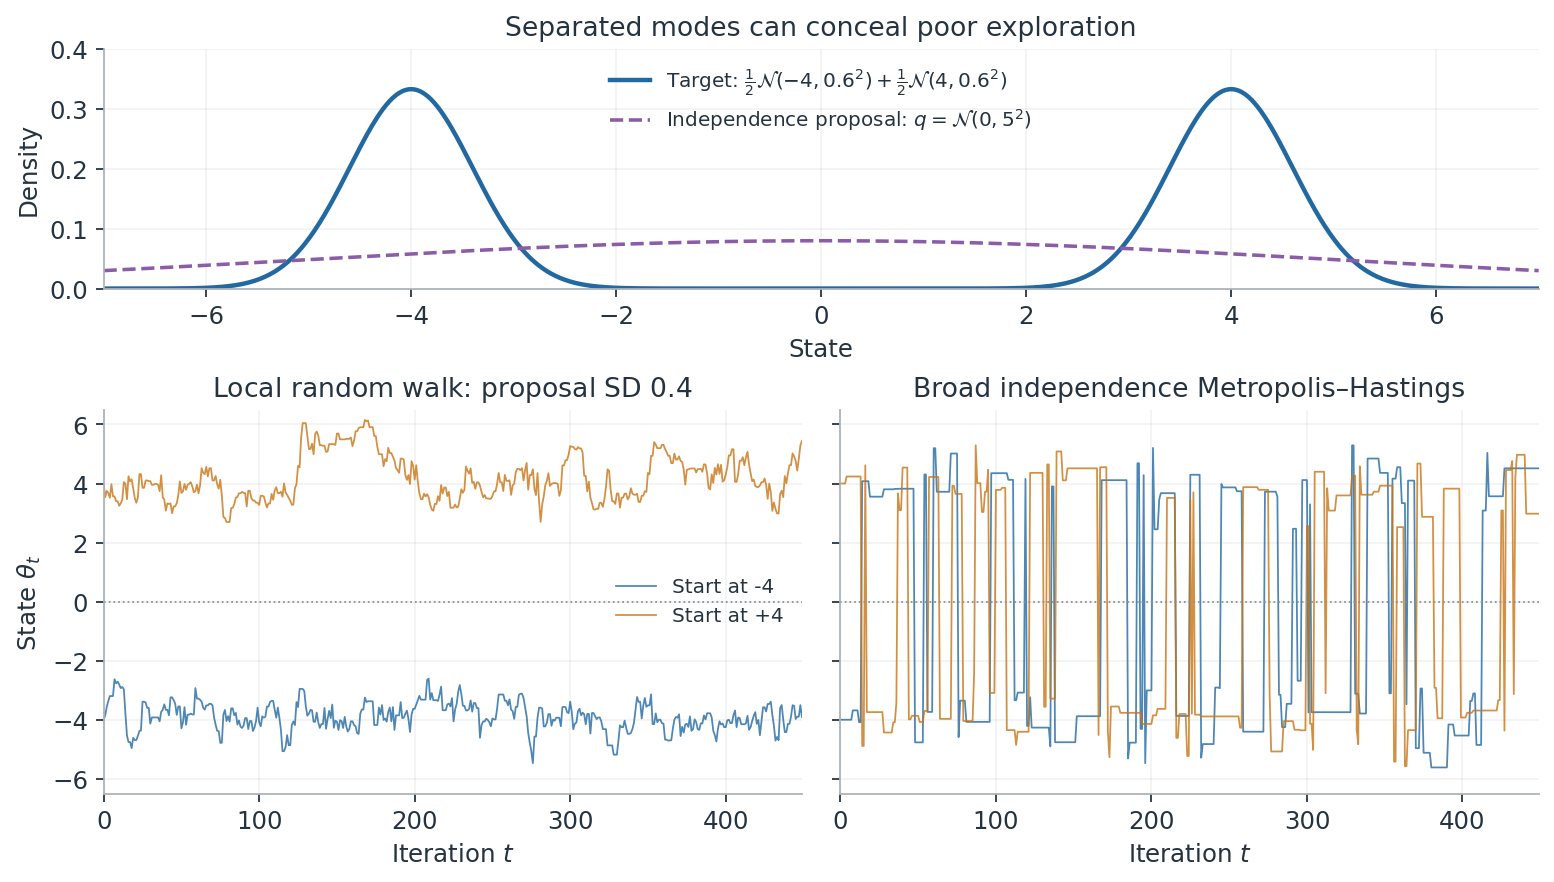

Separated local random walks can produce a plausible pooled distribution while retaining their initial modes. A broad independence proposal can move directly between modes when combined with the Hastings correction. These finite traces illustrate exploration; they do not prove convergence.


An independence proposal draws from the same $q$ regardless of the current
state: $q(y\mid x)=q(y)$. Take $q=\mathcal N(0,5^2)$ so proposals can reach
both modes. Independence does not mean symmetry of the conditional densities:
in general $q(y)\ne q(x)$. The correct log acceptance is
$$\log\alpha(x,y)=\min\big(0,\log\pi_{\mathrm{mix}}(y)
  -\log\pi_{\mathrm{mix}}(x)+\log q(x)-\log q(y)\big).$$
To see what happens if the proposal correction is omitted, define
$h(x)\propto\pi_{\mathrm{mix}}(x)q(x)$. The correct independence-MH ratio for
$h$ is
$$\frac{h(y)q(x)}{h(x)q(y)}
  =\frac{\pi_{\mathrm{mix}}(y)}{\pi_{\mathrm{mix}}(x)}.$$
Thus the target-only rule would have invariant density $h$, rather than the
desired mixture. More iterations would estimate the wrong distribution more
precisely. Here $h$ is still symmetric, so checking only its mean and sign
probability would not detect the mistake; the density and variance also matter.

### Task A — General Metropolis–Hastings acceptance

1. Implement `mh_log_accept`. Its inputs are target log densities at the current
   and candidate states, followed by the forward $\log q(y\mid x)$ and reverse
   $\log q(x\mid y)$ proposal log densities.
2. Enable the appendix and compare the local random walk with the independence
   sampler. Inspect per-chain positive-mode fractions and mode-switch counts,
   as well as pooled estimates and split Rhat.
3. Explain why a high acceptance rate or accurate pooled mean can be misleading
   for separated modes, and why the independence proposal needs a correction.


In [13]:
def mh_log_accept(lp_current, lp_candidate, lq_forward, lq_reverse):
    '''Broadcastable log densities; current target log density must be finite.

    Return log(alpha), capped at zero. Forward means q(candidate | current).
    '''
    return np.minimum(0., lp_candidate-lp_current+lq_reverse-lq_forward)


In [14]:
if RUN_APPENDIX:
    def test_general_acceptance():
        np.testing.assert_allclose(mh_log_accept(0., -2., -3., -1.), 0.)
        np.testing.assert_allclose(mh_log_accept(0., -2., -1., -3.), -4.)
        np.testing.assert_allclose(mh_log_accept(5., 4., 0., 0.), -1.)
        assert np.isneginf(mh_log_accept(0., -np.inf, -1., -1.))
        # Detailed balance for an asymmetric pair, in log probability flow.
        lp_x, lp_y, forward, reverse = -1.3, -2.7, -0.8, -1.1
        flow_xy = lp_x + forward + mh_log_accept(lp_x, lp_y, forward, reverse)
        flow_yx = lp_y + reverse + mh_log_accept(lp_y, lp_x, reverse, forward)
        np.testing.assert_allclose(flow_xy, flow_yx)
    check_task("A", test_general_acceptance)
else:
    print("Appendix disabled. Set RUN_APPENDIX = True in setup to enable it.")


Task A: checks passed.


Local RW, chain 1: positive fraction 0.000; mode switches 0
Local RW, chain 2: positive fraction 0.000; mode switches 0
Local RW, chain 3: positive fraction 1.000; mode switches 0
Local RW, chain 4: positive fraction 1.000; mode switches 0
Independence MH, chain 1: positive fraction 0.493; mode switches 776
Independence MH, chain 2: positive fraction 0.484; mode switches 768
Independence MH, chain 3: positive fraction 0.504; mode switches 772
Independence MH, chain 4: positive fraction 0.503; mode switches 800


| Method | Mean (exact 0) | P(X>0) (exact .5) | Accept | Classic split Rhat |
| --- | --- | --- | --- | --- |
| Local RW | 0.015193 | 0.5 | 0.79428 | 7.1444 |
| Independence MH | -0.035256 | 0.49604 | 0.22394 | 1.001 |

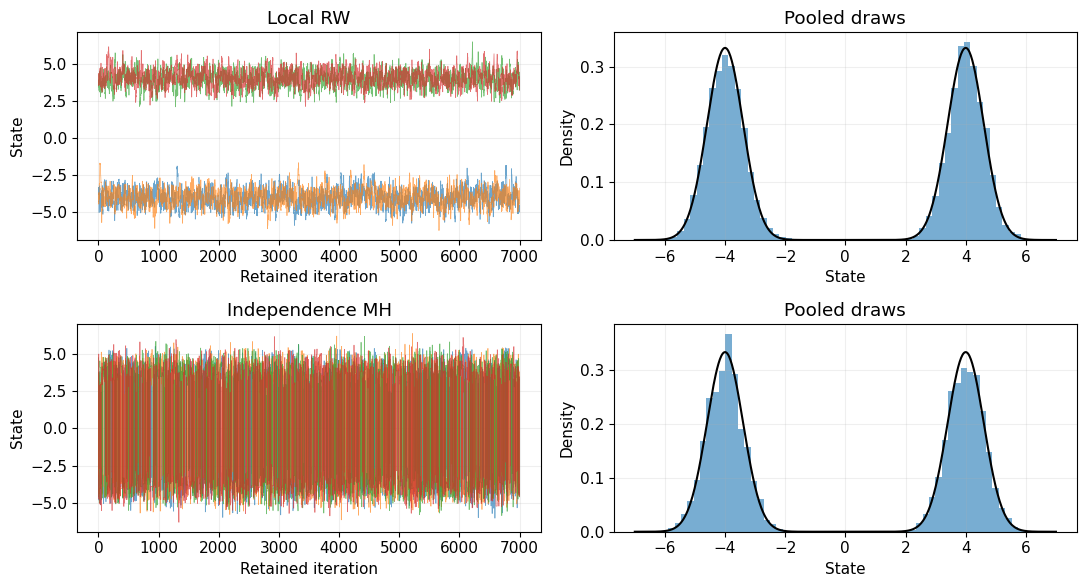

In [15]:
def log_mixture(x):
    components = np.stack([norm.logpdf(x, -4., 0.6), norm.logpdf(x, 4., 0.6)])
    return logsumexp(components, axis=0)-np.log(2.)

def independence_metropolis(log_density, initial, n_steps, rng):
    current = np.array(initial, dtype=float, copy=True)
    lp_current = log_density(current)
    samples = np.empty((len(current), n_steps))
    accepted = np.zeros(len(current))
    for t in range(n_steps):
        candidate = rng.normal(0., 5., size=len(current))
        lp_candidate = log_density(candidate)
        log_alpha = mh_log_accept(lp_current, lp_candidate,
                                  norm.logpdf(candidate, 0., 5.),
                                  norm.logpdf(current, 0., 5.))
        accept = np.log(rng.random(len(current))) < log_alpha
        current = np.where(accept, candidate, current)
        lp_current = np.where(accept, lp_candidate, lp_current)
        accepted += accept
        samples[:, t] = current
    return samples, accepted/n_steps

if RUN_APPENDIX and ready(3, "A"):
    mixture_initial = np.array([-4., -4., 4., 4.])
    local = random_walk_metropolis(log_mixture, mixture_initial, 0.4, 8000,
                                   np.random.default_rng(40))
    global_ = independence_metropolis(log_mixture, mixture_initial, 8000,
                                     np.random.default_rng(41))
    appendix_rows = []
    fig, axes = plt.subplots(2, 2, figsize=(11, 6))
    mixture_grid = np.linspace(-7, 7, 600)
    for row, (name, (samples, rates)) in enumerate(
            [("Local RW", local), ("Independence MH", global_)]):
        retained = samples[:, 1000:]
        appendix_rows.append([name, retained.mean(), (retained > 0).mean(),
                              rates.mean(), classic_split_rhat(retained)])
        for j, chain in enumerate(retained):
            switches = np.sum((chain[1:] > 0) != (chain[:-1] > 0))
            print(f"{name}, chain {j+1}: positive fraction {(chain>0).mean():.3f}; "
                  f"mode switches {switches}")
            axes[row, 0].plot(chain, linewidth=0.5, alpha=0.65)
        axes[row, 0].set(title=name, xlabel="Retained iteration", ylabel="State")
        axes[row, 1].hist(retained.ravel(), bins=60, density=True, alpha=0.6)
        axes[row, 1].plot(mixture_grid, np.exp(log_mixture(mixture_grid)), color="black")
        axes[row, 1].set(xlabel="State", ylabel="Density", title="Pooled draws")
    table(["Method", "Mean (exact 0)", "P(X>0) (exact .5)", "Accept", "Classic split Rhat"],
          appendix_rows)
    plt.tight_layout()
    plt.show()


Solution. The local chains typically make no mode switches. Starting two
chains in each mode makes their pooled mean look correct by construction,
although each chain fails to explore the full distribution. Per-chain mode
fractions are near 0 or 1 and split Rhat flags strong disagreement. The
independence proposal trades some acceptance for frequent travel between modes.
Its Hastings correction is $\log q(x)-\log q(y)$. Omitting it yields stationary
density proportional to $\pi_{\rm mix}(x)q(x)$, not $\pi_{\rm mix}(x)$: applying
the independence-MH rule to that product cancels $q$ and leaves the incorrect
target-only ratio. More iterations reduce MC error around the wrong distribution.


## References

- Art B. Owen, Monte Carlo theory, methods and examples,
  [Chapter 9: importance sampling](https://artowen.su.domains/mc/Ch-var-is.pdf).
- Aki Vehtari, Andrew Gelman, Daniel Simpson, Bob Carpenter, and Paul-Christian
  Bürkner (2021), [Rank-normalization, folding, and localization: an improved
  Rhat for assessing convergence of MCMC](https://arxiv.org/abs/1903.08008).
- SciPy, [Beta distribution and parameterization](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.beta.html).
